# ESL Figure 2.1–2.4｜Python 模擬

使用相同的 **200 筆 training data** 重現 Least Squares、15-NN、1-NN，並以 **10,000 筆 test data** 比較錯誤率。執行 **Run All** 就能重新產生四張圖。

## 1. 模擬資料生成

**BLUE 中心：** $m_k^{(B)}\sim\mathcal N((1,0)^T,I)$ ；**ORANGE 中心：** $m_k^{(O)}\sim\mathcal N((0,1)^T,I)$。

每一類先抽 **10 個中心**。每筆資料隨機選一個中心 $m_k$，再從 $\mathcal N(m_k,I/5)$ 抽樣。

**參數：** train = 100 × 2；test = 5,000 × 2；`seed=7` 是自行指定，方便重現。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from scipy.stats import multivariate_normal

SEED = 7                       # 自行選定，供重現實驗
rng = np.random.default_rng(SEED)
I = np.eye(2)                  # 2x2 單位矩陣
Sigma = I / 5                 # 每個中心周圍的 covariance
n_centers = 10

blue_centers = rng.multivariate_normal([1, 0], I, size=n_centers)
orange_centers = rng.multivariate_normal([0, 1], I, size=n_centers)

def generate_from_mixture(centers, n):
    """每個樣本等機率選一個中心，再從 N(center, I/5) 抽樣。"""
    center_ids = rng.integers(0, len(centers), size=n)
    points = np.empty((n, 2))
    for i, k in enumerate(center_ids):
        points[i] = rng.multivariate_normal(centers[k], Sigma)
    return points

# Training: BLUE 100 + ORANGE 100
X_blue = generate_from_mixture(blue_centers, 100)
X_orange = generate_from_mixture(orange_centers, 100)
X_train = np.vstack([X_blue, X_orange])
y_train = np.r_[np.zeros(100, dtype=int), np.ones(100, dtype=int)]

# Test: BLUE 5000 + ORANGE 5000，沿用相同的 20 個中心
X_test = np.vstack([
    generate_from_mixture(blue_centers, 5000),
    generate_from_mixture(orange_centers, 5000)
])
y_test = np.r_[np.zeros(5000, dtype=int), np.ones(5000, dtype=int)]

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('20 centers:', blue_centers.shape, orange_centers.shape)

Train: (200, 2)  Test: (10000, 2)
20 centers: (10, 2) (10, 2)


### 畫決策邊界的網格

**參數：** $500\times500$ 個查詢位置；這些網格點只用來畫圖，**不是 training/test data**。

In [2]:
# 畫圖共同設定（以下四張圖共用）
all_points = np.vstack([X_train, blue_centers, orange_centers])
x_min, y_min = all_points.min(axis=0) - 1.0
x_max, y_max = all_points.max(axis=0) + 1.0
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)
grid = np.c_[xx.ravel(), yy.ravel()]  # (250000, 2)

def show_boundary(Z, levels, title):
    fig, ax = plt.subplots(figsize=(7, 6.6))
    ax.contourf(xx, yy, Z, levels=levels,
                colors=['lightskyblue', 'moccasin'], alpha=0.35)
    ax.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.7)
    ax.scatter(X_blue[:, 0], X_blue[:, 1], c='royalblue',
               s=28, edgecolors='black', linewidths=0.3, label='BLUE')
    ax.scatter(X_orange[:, 0], X_orange[:, 1], c='orange',
               s=28, edgecolors='black', linewidths=0.3, label='ORANGE')
    ax.set(xlabel='$X_1$', ylabel='$X_2$', title=title,
           xlim=(x_min, x_max), ylim=(y_min, y_max))
    ax.legend(loc='best')
    fig.tight_layout()
    plt.show()
    plt.close(fig)

print('Grid:', grid.shape)

Grid: (250000, 2)


## Figure 2.1 — Least Squares Classification

**參數：** $N=200$、BLUE = 0、ORANGE = 1、分類閾值 **0.5**。用線性迴歸的預測值決定類別。

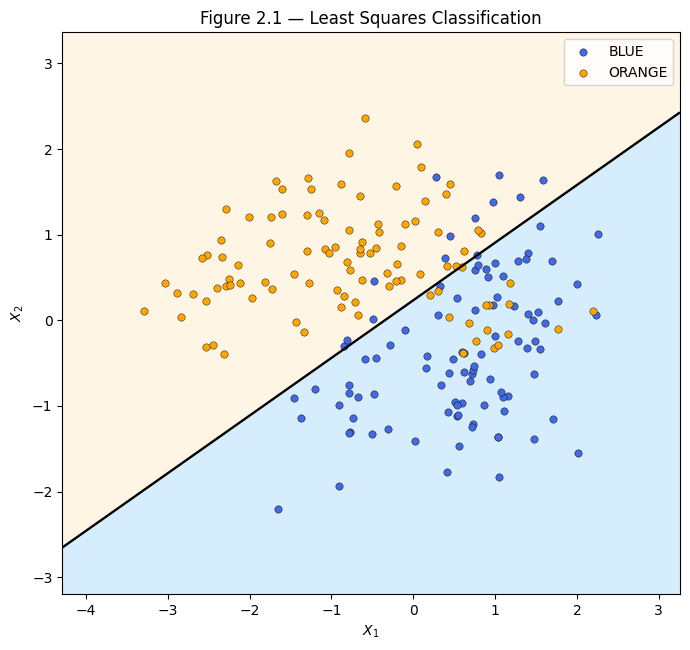

In [3]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

score = linear_model.predict(grid)             # 線性預測值，不保證在 [0,1]
pred = (score > 0.5).astype(int)               # >0.5 判 ORANGE
Z = score.reshape(xx.shape)

show_boundary(Z, [-100, 0.5, 100], 'Figure 2.1 — Least Squares Classification')

## Figure 2.2 — 15-Nearest Neighbors

**參數：** $N=200$、**$k=15$**、Euclidean distance、uniform voting。每個位置取最近 15 個訓練點，以多數決分類。

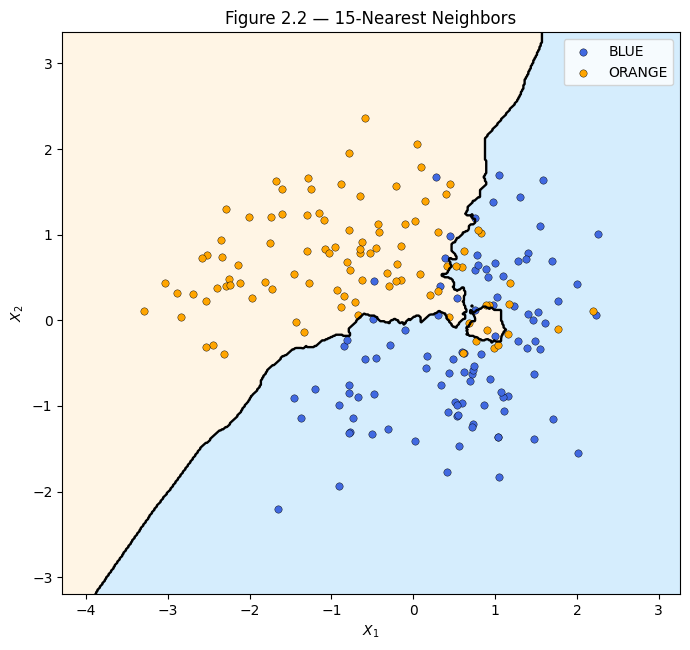

In [4]:
knn15 = KNeighborsClassifier(n_neighbors=15)
knn15.fit(X_train, y_train)

pred = knn15.predict(grid)                     # 0=BLUE, 1=ORANGE
prob_orange = knn15.predict_proba(grid)[:, 1]  # ORANGE 鄰居比例
Z = prob_orange.reshape(xx.shape)

show_boundary(Z, [0, 0.5, 1], 'Figure 2.2 — 15-Nearest Neighbors')

## Figure 2.3 — 1-Nearest Neighbor

**參數：** $N=200$、**$k=1$**、Euclidean distance。每個位置由最近的一筆訓練資料決定類別。

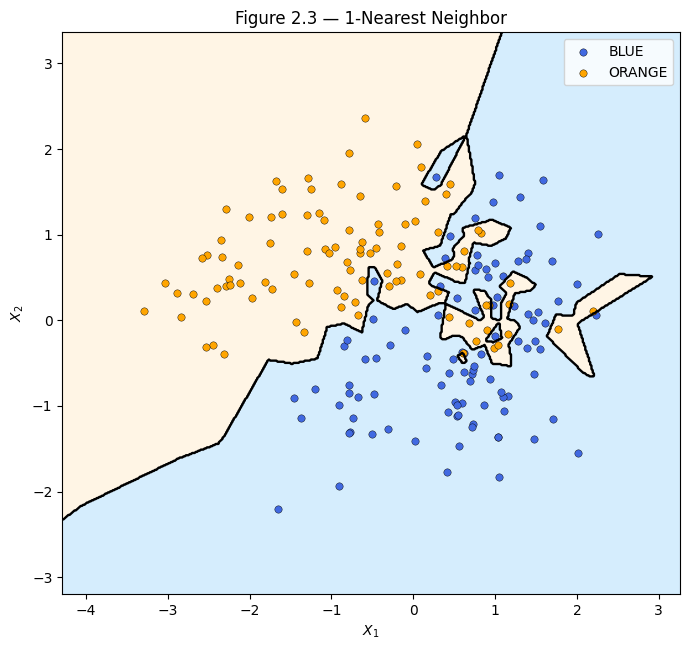

In [5]:
knn1 = KNeighborsClassifier(n_neighbors=1)
knn1.fit(X_train, y_train)

pred = knn1.predict(grid)
Z = pred.reshape(xx.shape)

show_boundary(Z, [-0.5, 0.5, 1.5], 'Figure 2.3 — 1-Nearest Neighbor')

## Figure 2.4 — Training / Test Misclassification Error

**參數：** train = **200**、test = **10,000**、不同的 $k$；橫軸為近似模型複雜度 **$N/k$**。

藍線是 training error，橘線是 test error；方塊為 Least Squares，紫線為以 test sample **估計**的 Bayes error。

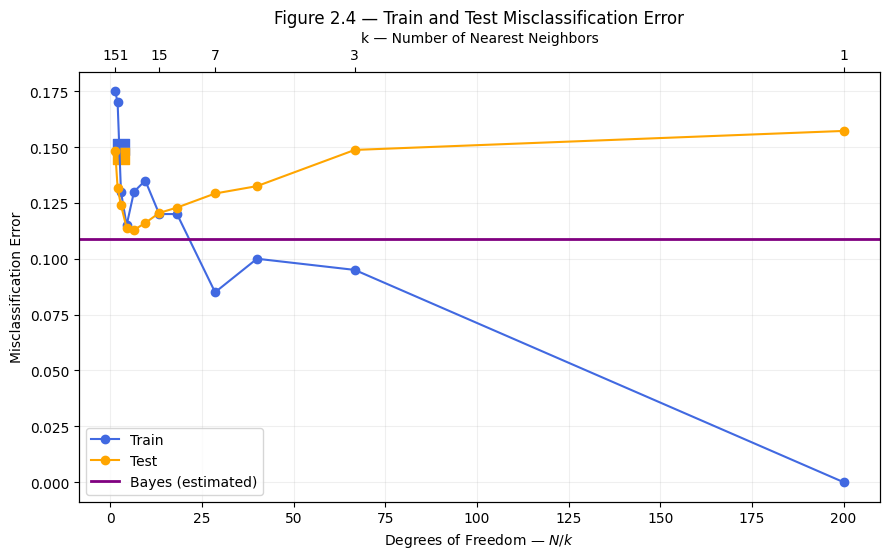

Least Squares: train error=0.1500, test error=0.1460
Estimated Bayes error=0.1089
k       N/k   train error   test error
151      1.32      0.1750       0.1482
101      1.98      0.1700       0.1318
 69      2.90      0.1300       0.1240
 45      4.44      0.1150       0.1138
 31      6.45      0.1300       0.1129
 21      9.52      0.1350       0.1160
 15     13.33      0.1200       0.1205
 11     18.18      0.1200       0.1229
  7     28.57      0.0850       0.1292
  5     40.00      0.1000       0.1325
  3     66.67      0.0950       0.1487
  1    200.00      0.0000       0.1572


In [6]:
k_values = np.array([151, 101, 69, 45, 31, 21, 15, 11, 7, 5, 3, 1])
train_err, test_err = [], []

for k in k_values:
    clf = KNeighborsClassifier(n_neighbors=int(k))
    clf.fit(X_train, y_train)
    train_err.append(1 - clf.score(X_train, y_train))
    test_err.append(1 - clf.score(X_test, y_test))

train_err = np.array(train_err)
test_err = np.array(test_err)
df = len(X_train) / k_values

# Least Squares 的 train / test error，閾值均為 0.5
linear_train_error = np.mean((linear_model.predict(X_train) > 0.5) != y_train)
linear_test_error = np.mean((linear_model.predict(X_test) > 0.5) != y_test)

# 依已知 Gaussian mixture 分布計算 Bayes rule（用 test set 估計錯誤率）
def mixture_density(X, centers):
    return sum(multivariate_normal.pdf(X, mean=c, cov=Sigma)
               for c in centers) / len(centers)

bayes_pred = (mixture_density(X_test, orange_centers) >
              mixture_density(X_test, blue_centers)).astype(int)
bayes_error = np.mean(bayes_pred != y_test)

fig, ax = plt.subplots(figsize=(9, 5.7))
ax.plot(df, train_err, 'o-', color='royalblue', label='Train')
ax.plot(df, test_err, 'o-', color='orange', label='Test')
ax.axhline(bayes_error, color='purple', linewidth=2, label='Bayes (estimated)')
ax.scatter(3, linear_train_error, s=130, marker='s', color='royalblue')
ax.scatter(3, linear_test_error, s=130, marker='s', color='orange')
ax.set(xlabel='Degrees of Freedom — $N/k$', ylabel='Misclassification Error',
       title='Figure 2.4 — Train and Test Misclassification Error')
ax.legend()
ax.grid(alpha=0.2)
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
# 只標幾個代表性的 k，避免刻度文字互相重疊
show_ks = np.array([151, 15, 7, 3, 1])
ax_top.set_xticks(len(X_train) / show_ks)
ax_top.set_xticklabels(show_ks)
ax_top.set_xlabel('k — Number of Nearest Neighbors')
fig.tight_layout()
plt.show()
plt.close(fig)

print(f'Least Squares: train error={linear_train_error:.4f}, test error={linear_test_error:.4f}')
print(f'Estimated Bayes error={bayes_error:.4f}')
print('k       N/k   train error   test error')
for k, d, tr, te in zip(k_values, df, train_err, test_err):
    print(f'{k:3d}  {d:8.2f}      {tr:.4f}       {te:.4f}')